In [23]:
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult (1).csv


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
import statsmodels.api as sm
from IPython.display import display
warnings.filterwarnings("ignore")
SEED = 56
np.random.seed(SEED)

In [25]:
import io
filename = next(f for f in uploaded if f.lower().endswith(".csv"))
df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    header=None,
    skipinitialspace=True)
columns = [
    "age", "workclass", "fnlwgt", "education", "education.num",
    "marital.status", "occupation", "relationship", "race", "sex",
    "capital.gain", "capital.loss", "hours.per.week",
    "native.country", "income"
]
if str(df.iloc[0, 0]).strip().lower() == "age":
    df = df.iloc[1:].copy()
df.columns = columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().str.rstrip(".")
df = df.replace("?", np.nan)
df["income_binary"] = (df["income"] == ">50K").astype(int)
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))
print("\nIncome distribution:")
display(df["income"].value_counts())

Dataset shape: (32561, 16)

First five rows:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,income_binary
1,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K,0
2,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,0
3,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K,0
4,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K,0
5,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K,0



Missing values:


,Missing Count
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0



Income distribution:


,count
income,
<=50K,24720
>50K,7841


In [26]:
numeric_features = [
    "age", "fnlwgt", "education.num",
    "capital.gain", "capital.loss", "hours.per.week"]

categorical_features = [
    "workclass", "education", "marital.status",
    "occupation", "relationship", "race", "sex",
    "native.country"]
X = df[numeric_features + categorical_features]
y = df["income_binary"]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training percentage:", round(X_train.shape[0] / len(X) * 100, 2))
print("Testing percentage:", round(X_test.shape[0] / len(X) * 100, 2))

Training rows: 22792
Testing rows: 9769
Training percentage: 70.0
Testing percentage: 30.0


,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,28.0,48.0,-2.0,78.0,143,0.44
1,fnlwgt,117827.0,237051.0,-61009.0,415887.0,992,3.05
2,education.num,9.0,12.0,4.5,16.5,1198,3.68
3,capital.gain,0.0,0.0,0.0,0.0,2712,8.33
4,capital.loss,0.0,0.0,0.0,0.0,1519,4.67
5,hours.per.week,40.0,45.0,32.5,52.5,9008,27.66


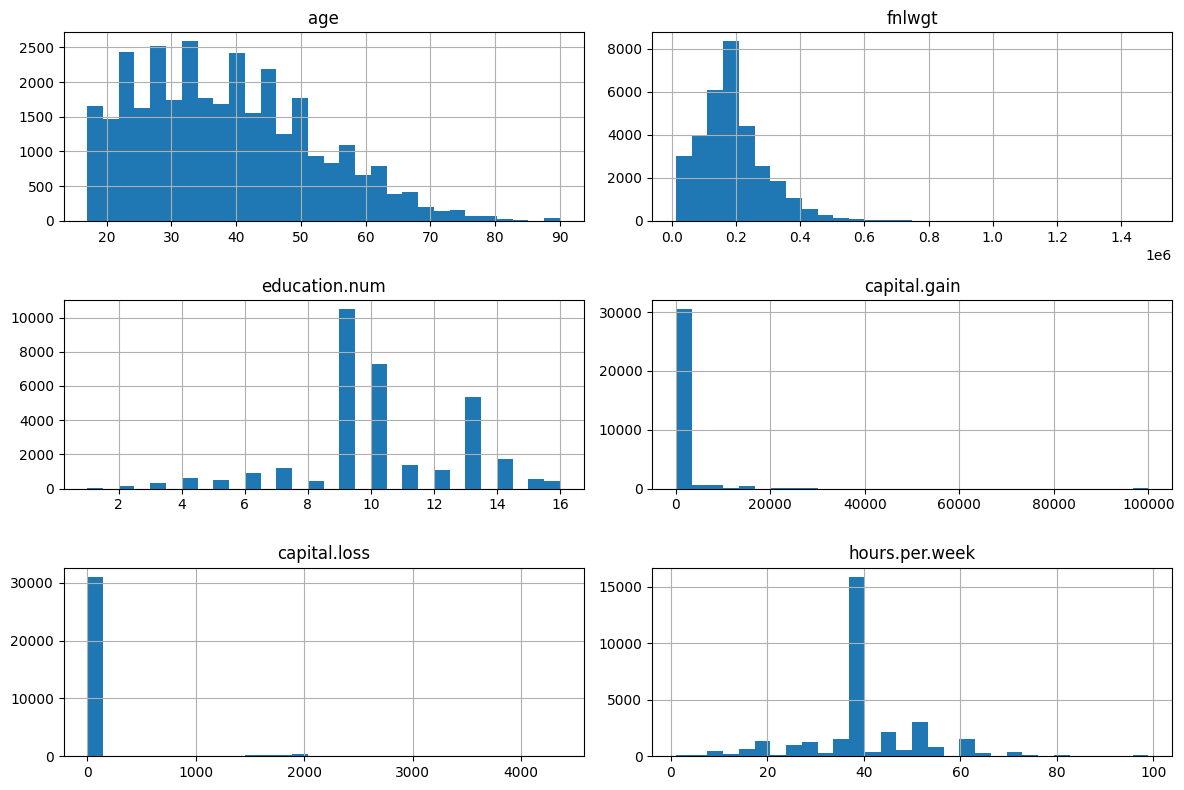

In [27]:
outlier_results = []
for col in numeric_features:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((values < lower) | (values > upper)).sum()
    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier Percentage": count / len(values) * 100
    })
outlier_table = pd.DataFrame(outlier_results)
display(outlier_table.round(2))
plot_df = df[numeric_features].apply(pd.to_numeric, errors='coerce')
plot_df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

In [28]:
# Model A: Linear Regression
model_a = LinearRegression()
model_a.fit(X_train, y_train)
linear_predictions = np.clip(
    model_a.predict(X_test), 0, 1)
median_threshold = np.median(linear_predictions)

linear_class = (
    linear_predictions >= median_threshold
).astype(int)
model_b = LogisticRegression(
    max_iter=1000,
    solver="liblinear",
    random_state=SEED)
model_b.fit(X_train, y_train)
logistic_probabilities = model_b.predict_proba(X_test)[:, 1]
logistic_class = (
    logistic_probabilities >= 0.5
).astype(int)
print("Median Linear Regression threshold:",
      round(median_threshold, 4))
print("Logistic Regression threshold: 0.5")
print("Linear Regression predictions:")
print(linear_class[:10])
print("Logistic Regression predictions:")
print(logistic_class[:10])

Median Linear Regression threshold: 0.2293
Logistic Regression threshold: 0.5
Linear Regression predictions:
[0 1 1 0 1 1 0 0 0 1]
Logistic Regression predictions:
[0 0 0 0 0 0 0 0 0 0]


In [29]:
cm = confusion_matrix(
    linear_class,
    logistic_class,
    labels=[0, 1])
print("Confusion Matrix")
print("Rows = Linear Regression")
print("Columns = Logistic Regression")
display(pd.DataFrame(
    cm,
    index=["Linear: Low", "Linear: High"],
    columns=["Logistic: Low", "Logistic: High"]))
mismatches = np.sum(linear_class != logistic_class)
mismatch_percentage = (
    mismatches / len(logistic_class)
) * 100
print("Total test cases:", len(y_test))
print("Mismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("\nLogistic Regression accuracy:",
      round(accuracy_score(y_test, logistic_class), 4))
print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, logistic_probabilities), 4))

Confusion Matrix
Rows = Linear Regression
Columns = Logistic Regression


,Logistic: Low,Logistic: High
Linear: Low,4868,16
Linear: High,3029,1856


Total test cases: 9769
Mismatched cases: 3045
Mismatch percentage: 31.17 %

Logistic Regression accuracy: 0.8465
Logistic Regression ROC-AUC: 0.9049


In [30]:
subgroup_df = df[
    ["age", "education.num", "hours.per.week",
     "capital.gain", "capital.loss", "sex", "income_binary"]
].copy()
for col in subgroup_df.columns:
    if subgroup_df[col].dtype == "object":
        subgroup_df[col] = subgroup_df[col].fillna(
            subgroup_df[col].mode()[0]
        )
    else:
        subgroup_df[col] = subgroup_df[col].fillna(
            subgroup_df[col].median()
        )
print("Sex distribution:")
display(subgroup_df["sex"].value_counts())
print("\nIncome rate by sex:")
display(
    subgroup_df.groupby("sex")["income_binary"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Proportion earning >50K"}))

Sex distribution:


,count
sex,
Male,21790
Female,10771



Income rate by sex:


,count,Proportion earning >50K
sex,,
Female,10771,0.109461
Male,21790,0.305737


In [31]:
def fit_logistic_statsmodels(data, predictors, target="income_binary"):
    X_sm = data[predictors].astype(float)
    X_sm = sm.add_constant(X_sm, has_constant="add")
    y_sm = data[target].astype(float)
    result = sm.Logit(y_sm, X_sm).fit(
        disp=False,
        maxiter=200 )
    confidence = result.conf_int()
    table = pd.DataFrame({
        "Coefficient": result.params,
        "CI Lower": confidence[0],
        "CI Upper": confidence[1],
        "P-value": result.pvalues })
    return result, table
subgroup_predictors = [
    "age", "education.num", "hours.per.week",
    "capital.gain", "capital.loss"]
subgroup_results = []
for group_name, data in [
    ("Full dataset", subgroup_df),
    ("Female", subgroup_df[subgroup_df["sex"] == "Female"]),
    ("Male", subgroup_df[subgroup_df["sex"] == "Male"])]:
    fitted_model, coefficient_table = fit_logistic_statsmodels(
        data, subgroup_predictors )
    row = coefficient_table.loc["education.num"]
    subgroup_results.append({
        "Group": group_name,
        "Sample Size": len(data),
        "Education Coefficient": row["Coefficient"],
        "CI Lower": row["CI Lower"],
        "CI Upper": row["CI Upper"],
        "P-value": row["P-value"]})
subgroup_table = pd.DataFrame(subgroup_results)
display(subgroup_table.round(4))

,Group,Sample Size,Education Coefficient,CI Lower,CI Upper,P-value
0,Full dataset,32561,0.3228,0.3094,0.3361,0.0
1,Female,10771,0.3453,0.3130,0.3776,0.0
2,Male,21790,0.3341,0.3189,0.3492,0.0


In [32]:
ovb_df = df[
    ["age", "education.num", "hours.per.week",
     "capital.gain", "capital.loss", "sex",
     "marital.status", "workclass", "income_binary"]
].copy()
for col in ovb_df.columns:
    if ovb_df[col].dtype == "object":
        ovb_df[col] = ovb_df[col].fillna(
            ovb_df[col].mode()[0]   )
    else:
        ovb_df[col] = ovb_df[col].fillna(
            ovb_df[col].median() )
ovb_df = pd.get_dummies(
    ovb_df,
    columns=["sex", "marital.status", "workclass"],
    drop_first=True,
    dtype=float)
full_predictors = [
    col for col in ovb_df.columns
    if col != "income_binary"]
full_model, full_table = fit_logistic_statsmodels(
    ovb_df, full_predictors)
reduced_predictors = [
    col for col in full_predictors
    if col != "education.num"]
reduced_model, reduced_table = fit_logistic_statsmodels(
    ovb_df, reduced_predictors)
print("Full model coefficients:")
display(full_table.round(4))
print("\nReduced model coefficients:")
display(reduced_table.round(4))

Full model coefficients:


,Coefficient,CI Lower,CI Upper,P-value
const,-8.3784,-8.7173,-8.0395,0.0000
age,0.0253,0.0223,0.0283,0.0000
education.num,0.3632,0.3479,0.3785,0.0000
hours.per.week,0.0319,0.0289,0.0348,0.0000
capital.gain,0.0003,0.0003,0.0003,0.0000
capital.loss,0.0007,0.0006,0.0007,0.0000
sex_Male,0.1379,0.0426,0.2333,0.0046
marital.status_Married-AF-spouse,2.6719,1.7589,3.5849,0.0000
marital.status_Married-civ-spouse,2.1115,1.9837,2.2393,0.0000
marital.status_Married-spouse-absent,-0.1594,-0.5906,0.2717,0.4686



Reduced model coefficients:


,Coefficient,CI Lower,CI Upper,P-value
const,-4.2747,-4.5413,-4.0081,0.0000
age,0.0220,0.0193,0.0248,0.0000
hours.per.week,0.0354,0.0326,0.0383,0.0000
capital.gain,0.0003,0.0003,0.0003,0.0000
capital.loss,0.0008,0.0007,0.0008,0.0000
sex_Male,0.0534,-0.0372,0.1440,0.2479
marital.status_Married-AF-spouse,2.4270,1.5304,3.3235,0.0000
marital.status_Married-civ-spouse,2.0209,1.8991,2.1428,0.0000
marital.status_Married-spouse-absent,-0.1364,-0.5462,0.2735,0.5143
marital.status_Never-married,-0.4372,-0.5900,-0.2843,0.0000


In [33]:
variables = [
    "age",
    "hours.per.week",
    "capital.gain",
    "capital.loss"]
comparison = []
for variable in variables:
    before = full_table.loc[variable, "Coefficient"]
    after = reduced_table.loc[variable, "Coefficient"]
    percentage_change = (
        (after - before) / abs(before) * 100
        if abs(before) > 1e-10 else np.nan )
    comparison.append({
        "Predictor": variable,
        "Full Coefficient": before,
        "Reduced Coefficient": after,
        "Absolute Change": abs(after - before),
        "Percentage Change (%)": percentage_change})
ovb_comparison = pd.DataFrame(comparison)
display(ovb_comparison.round(4))
largest_change = ovb_comparison.loc[
    ovb_comparison["Absolute Change"].idxmax()]
print("Largest coefficient shift:",
      largest_change["Predictor"])
print("Absolute shift:",
      round(largest_change["Absolute Change"], 4))
print("Percentage change:",
      round(largest_change["Percentage Change (%)"], 2), "%")

,Predictor,Full Coefficient,Reduced Coefficient,Absolute Change,Percentage Change (%)
0,age,0.0253,0.0220,0.0033,-12.8842
1,hours.per.week,0.0319,0.0354,0.0036,11.2009
2,capital.gain,0.0003,0.0003,0.0000,2.7292
3,capital.loss,0.0007,0.0008,0.0001,11.1448


Largest coefficient shift: hours.per.week
Absolute shift: 0.0036
Percentage change: 11.2 %


In [34]:
test_results = X_test_raw.reset_index(drop=True).copy()
test_results["Actual"] = np.asarray(y_test).astype(int)
test_results["Probability"] = logistic_probabilities
test_results["Prediction"] = logistic_class
test_results["Error Type"] = ""
false_positive = (
    (test_results["Probability"] >= 0.75) &
    (test_results["Actual"] == 0))
false_negative = (
    (test_results["Probability"] <= 0.25) &
    (test_results["Actual"] == 1))
test_results.loc[false_positive, "Error Type"] = "False Positive"
test_results.loc[false_negative, "Error Type"] = "False Negative"
wrong_cases = test_results[
    test_results["Error Type"] != ""
].copy()
wrong_count = len(wrong_cases)
wrong_percentage = wrong_count / len(test_results) * 100

print("Total test cases:", len(test_results))
print("High-confidence wrong predictions:", wrong_count)
print("Percentage of test set:", round(wrong_percentage, 2), "%")

# Select at most 50 rows
if len(wrong_cases) > 50:
    adversarial_subset = wrong_cases.sample(
        n=50, random_state=SEED
    )
else:
    adversarial_subset = wrong_cases.copy()

print("Adversarial subset size:", len(adversarial_subset))

display(adversarial_subset.head(10))

Total test cases: 9769
High-confidence wrong predictions: 485
Percentage of test set: 4.96 %
Adversarial subset size: 50


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass,education,marital.status,occupation,relationship,race,sex,native.country,Actual,Probability,Prediction,Error Type
2150,52,240013,14,0,0,70,Self-emp-not-inc,Masters,Married-civ-spouse,Sales,Husband,White,Male,United-States,0,0.826324,1,False Positive
3713,52,63004,14,0,0,40,Self-emp-not-inc,Masters,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,Philippines,0,0.821087,1,False Positive
1490,36,129150,9,0,0,50,Self-emp-not-inc,HS-grad,Married-civ-spouse,Farming-fishing,Husband,White,Male,United-States,1,0.080059,0,False Negative
8905,58,214502,5,0,0,50,Private,9th,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,United-States,1,0.097465,0,False Negative
5910,48,121124,10,0,0,40,Private,Some-college,Married-civ-spouse,Other-service,Husband,White,Male,United-States,1,0.185462,0,False Negative
2031,78,237294,9,0,0,45,Self-emp-inc,HS-grad,Widowed,Sales,Not-in-family,White,Male,United-States,1,0.221531,0,False Negative
5214,61,80896,9,0,0,45,Private,HS-grad,Separated,Transport-moving,Unmarried,Asian-Pac-Islander,Male,United-States,1,0.058532,0,False Negative
3863,46,113390,14,0,1740,60,Private,Masters,Married-civ-spouse,Adm-clerical,Husband,White,Male,United-States,0,0.907413,1,False Positive
4908,50,101094,14,0,0,55,Self-emp-inc,Masters,Married-civ-spouse,Sales,Husband,White,Male,United-States,0,0.827242,1,False Positive
1736,51,43354,7,0,0,40,Private,11th,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States,1,0.144995,0,False Negative


In [37]:
print("Error types in the adversarial subset:")
display(adversarial_subset["Error Type"].value_counts())
gender_comparison = pd.DataFrame({
    "Full Test Set (%)":
        test_results["sex"].value_counts(normalize=True) * 100,
    "Adversarial Subset (%)":
        adversarial_subset["sex"].value_counts(normalize=True) * 100
}).fillna(0)
display(gender_comparison.round(2))
print("Full test set age statistics:")
display(test_results["age"].describe().round(2))
print("Adversarial subset age statistics:")
display(adversarial_subset["age"].describe().round(2))
characteristics = [
    "age", "education.num", "hours.per.week",
    "capital.gain", "capital.loss"]
print("Adversarial subset numerical characteristics:")
display(adversarial_subset[characteristics].describe().round(2))

adversarial_subset.to_csv(
    "adversarial_subset.csv", index=False)
files.download("adversarial_subset.csv")

Error types in the adversarial subset:


,count
Error Type,
False Negative,37
False Positive,13


,Full Test Set (%),Adversarial Subset (%)
sex,,
Male,67.57,88.0
Female,32.43,12.0


Full test set age statistics:


,age
count,9769
unique,71
top,36
freq,282


...

,age
count,50
unique,28
top,31
freq,4


Adversarial subset numerical characteristics:


,age,education.num,hours.per.week,capital.gain,capital.loss
count,50,50,50,50,50
unique,28,12,14,6,2
top,31,9,40,0,0
freq,4,17,21,45,48


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
fairness_data = test_results.copy()
fairness_data["Group"] = np.where(
    fairness_data["sex"] == "Male",
    "Male",
    "Female")
def ratio(a, b):
    if b == 0 or np.isnan(a) or np.isnan(b):
        return np.nan
    return a / b
fairness_rows = []
thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)
for threshold in thresholds:
    predictions = (
        fairness_data["Probability"] >= threshold
    ).astype(int)
    group_metrics = {}
    for group in ["Male", "Female"]:
        group_data = fairness_data[
            fairness_data["Group"] == group ]
        actual = group_data["Actual"].to_numpy()
        predicted = predictions.loc[group_data.index].to_numpy()
        tp = np.sum((actual == 1) & (predicted == 1))
        fp = np.sum((actual == 0) & (predicted == 1))
        fn = np.sum((actual == 1) & (predicted == 0))
        tn = np.sum((actual == 0) & (predicted == 0))
        selection_rate = np.mean(predicted)
        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        group_metrics[group] = {
            "Selection Rate": selection_rate,
            "TPR": tpr,
            "FPR": fpr,
            "PPV": ppv
        }
    male = group_metrics["Male"]
    female = group_metrics["Female"]
    dp = ratio(
        male["Selection Rate"],
        female["Selection Rate"]
    )
    tpr_ratio = ratio(male["TPR"], female["TPR"])
    fpr_ratio = ratio(male["FPR"], female["FPR"])

    valid_eo_ratios = [
        value for value in [tpr_ratio, fpr_ratio]
        if not np.isnan(value)
    ]
    eo = min(valid_eo_ratios) if valid_eo_ratios else np.nan
    pp = ratio(male["PPV"], female["PPV"])
    fairness_rows.append({
        "Threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "Male Selection Rate": male["Selection Rate"],
        "Female Selection Rate": female["Selection Rate"],
        "Male TPR": male["TPR"],
        "Female TPR": female["TPR"],
        "Male FPR": male["FPR"],
        "Female FPR": female["FPR"],
        "Male PPV": male["PPV"],
        "Female PPV": female["PPV"],
        "Accuracy": accuracy_score(
            fairness_data["Actual"], predictions
        )
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(4))

,Threshold,DP,EO,PP,Male Selection Rate,Female Selection Rate,Male TPR,Female TPR,Male FPR,Female FPR,Male PPV,Female PPV,Accuracy
0,0.05,2.2335,1.0393,1.2732,0.7332,0.3283,0.9890,0.9516,0.6220,0.2506,0.4089,0.3212,0.6309
1,0.15,3.1085,1.1665,1.0267,0.5760,0.1853,0.9405,0.8063,0.4174,0.1079,0.4950,0.4821,0.7532
2,0.25,3.2253,1.1865,1.0065,0.4551,0.1411,0.8586,0.7236,0.2796,0.0685,0.5719,0.5682,0.8097
3,0.35,3.2783,1.2401,1.0350,0.3549,0.1083,0.7596,0.6125,0.1789,0.0454,0.6487,0.6268,0.8395
4,0.45,3.4795,1.2900,1.0143,0.2812,0.0808,0.6542,0.5071,0.1189,0.0277,0.7053,0.6953,0.8475
5,0.55,3.5982,1.2369,0.9405,0.2215,0.0616,0.5497,0.4444,0.0787,0.0138,0.7524,0.8000,0.8468
6,0.65,3.5815,1.2488,0.9540,0.1662,0.0464,0.4483,0.3590,0.0435,0.0075,0.8177,0.8571,0.8413
7,0.75,3.5058,1.2559,0.9801,0.1162,0.0331,0.3363,0.2678,0.0204,0.0039,0.8774,0.8952,0.8270
8,0.85,3.6894,1.3498,1.0010,0.0745,0.0202,0.2269,0.1681,0.0083,0.0018,0.9228,0.9219,0.8073
9,0.95,3.1595,1.1815,1.0231,0.0359,0.0114,0.1144,0.0969,0.0017,0.0007,0.9662,0.9444,0.7851


Available columns: ['Threshold', 'DP', 'EO', 'PP', 'Male Selection Rate', 'Female Selection Rate', 'Male TPR', 'Female TPR', 'Male FPR', 'Female FPR', 'Male PPV', 'Female PPV', 'Accuracy']


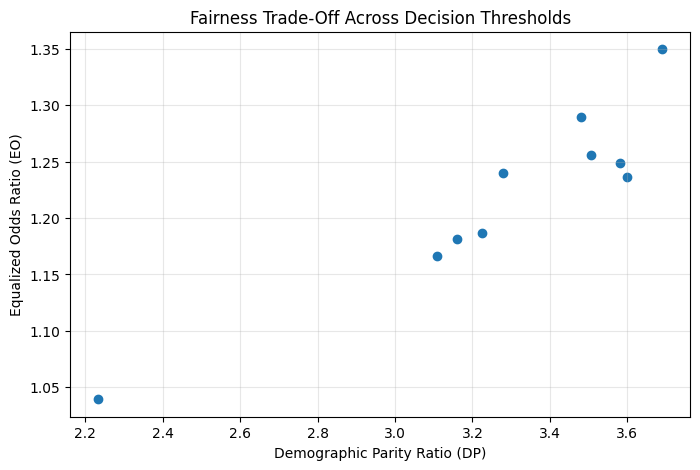

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

print("Available columns:", fairness_table.columns.tolist())
dp_col = "DP"
eo_col = "EO"

if dp_col in fairness_table.columns and eo_col in fairness_table.columns:
    plot_data = fairness_table[[dp_col, eo_col]].copy()
    plot_data[dp_col] = pd.to_numeric(plot_data[dp_col], errors="coerce")
    plot_data[eo_col] = pd.to_numeric(plot_data[eo_col], errors="coerce")
    plot_data = plot_data.dropna()
    if len(plot_data) > 0:
        plt.figure(figsize=(8, 5))
        plt.scatter(plot_data[dp_col], plot_data[eo_col])
        plt.xlabel("Demographic Parity Ratio (DP)")
        plt.ylabel("Equalized Odds Ratio (EO)")
        plt.title("Fairness Trade-Off Across Decision Thresholds")
        plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print("No valid values available to plot. Check the fairness calculations.")
else:
    print("Column names do not match. Use the column names printed above.")

In [45]:
best_example = None
for i in range(len(fairness_table)):
    for j in range(len(fairness_table)):
        first = fairness_table.iloc[i]
        second = fairness_table.iloc[j]
        if i == j:
            continue
        if (
            pd.notna(first["DP"]) and
            pd.notna(second["DP"]) and
            pd.notna(first["EO"]) and
            pd.notna(second["EO"]) and
            first["DP"] > 0 and
            first["EO"] > 0 and
            second["DP"] > first["DP"] and
            second["EO"] < first["EO"]
        ):
            dp_gain = (
                (second["DP"] - first["DP"]) /
                abs(first["DP"])
            ) * 100

            eo_loss = (
                (first["EO"] - second["EO"]) /
                abs(first["EO"])
            ) * 100

            if best_example is None or dp_gain > best_example["DP Gain (%)"]:
                best_example = {
                    "Starting Threshold": first["Threshold"],
                    "New Threshold": second["Threshold"],
                    "Starting DP": first["DP"],
                    "New DP": second["DP"],
                    "DP Gain (%)": dp_gain,
                    "Starting EO": first["EO"],
                    "New EO": second["EO"],
                    "EO Loss (%)": eo_loss
                }
if best_example is not None:
    display(pd.DataFrame([best_example]).round(4))
else:
    print(
        "No pair with increasing DP and decreasing EO was found. "
        "Inspect the fairness table and report an actual comparison "
        "supported by your results."
    )

,Starting Threshold,New Threshold,Starting DP,New DP,DP Gain (%),Starting EO,New EO,EO Loss (%)
0,0.35,0.55,3.2783,3.5982,9.7576,1.2401,1.2369,0.2615


In [46]:
print("=" * 55)
print("PART 1: MODEL COMPARISON")
print("=" * 55)
print("Median Linear Regression threshold:",
      round(median_threshold, 4))
print("Mismatches:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Logistic accuracy:",
      round(accuracy_score(y_test, logistic_class), 4))
print("Logistic ROC-AUC:",
      round(roc_auc_score(y_test, logistic_probabilities), 4))
print("\nPART 2.1: SUBGROUP ANALYSIS")
display(subgroup_table.round(4))
print("\nPART 2.2: OMITTED-VARIABLE BIAS")
display(ovb_comparison.round(4))
print("\nPART 2.3: ADVERSARIAL SUBSET")
print("High-confidence wrong cases:", wrong_count)
print("Percentage of test set:", round(wrong_percentage, 2), "%")
print("Rows in selected subset:", len(adversarial_subset))
print("\nPART 2.4: FAIRNESS METRICS")
display(
    fairness_table[
        ["Threshold", "DP", "EO", "PP", "Accuracy"]
    ].round(4)
)
subgroup_table.to_csv("subgroup_results.csv", index=False)
ovb_comparison.to_csv("omitted_variable_results.csv", index=False)
fairness_table.to_csv("fairness_results.csv", index=False)
print("\nResults tables saved successfully.")
files.download("subgroup_results.csv")
files.download("omitted_variable_results.csv")
files.download("fairness_results.csv")

PART 1: MODEL COMPARISON
Median Linear Regression threshold: 0.2293
Mismatches: 3045
Mismatch percentage: 31.17 %
Logistic accuracy: 0.8465
Logistic ROC-AUC: 0.9049

PART 2.1: SUBGROUP ANALYSIS


,Group,Sample Size,Education Coefficient,CI Lower,CI Upper,P-value
0,Full dataset,32561,0.3228,0.3094,0.3361,0.0
1,Female,10771,0.3453,0.3130,0.3776,0.0
2,Male,21790,0.3341,0.3189,0.3492,0.0



PART 2.2: OMITTED-VARIABLE BIAS


,Predictor,Full Coefficient,Reduced Coefficient,Absolute Change,Percentage Change (%)
0,age,0.0253,0.0220,0.0033,-12.8842
1,hours.per.week,0.0319,0.0354,0.0036,11.2009
2,capital.gain,0.0003,0.0003,0.0000,2.7292
3,capital.loss,0.0007,0.0008,0.0001,11.1448



PART 2.3: ADVERSARIAL SUBSET
High-confidence wrong cases: 485
Percentage of test set: 4.96 %
Rows in selected subset: 50

PART 2.4: FAIRNESS METRICS


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>